# Paper-aligned No-Context baseline trên CUB-200-2011

Notebook này tái hiện baseline **No-Context** trong paper: model chỉ nhận một query image, không dùng candidate pool, reference image, Selector, retrieval, Gumbel-Softmax hoặc policy-gradient.

Pipeline: `query image -> DINOv3 ViT-S/16 -> classification head -> class_id 0..199 + tên chim`.

Cấu hình bám theo phần Implementation Details của paper: ảnh `256x256`, batch size `64`, `100` epochs, AdamW, cosine annealing, horizontal/vertical flip, random resize crop và metric top-1 accuracy. Paper báo cáo trung bình trên ba random seeds; notebook này chạy một seed mỗi lần, có thể đổi `SEED` để chạy các seed khác.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Dataset CUB-200-2011

Dataset phải giữ cấu trúc gốc:

```text
CUB_200_2011/
  CUB_200_2011/
    images/
    classes.txt
    images.txt
    image_class_labels.txt
    train_test_split.txt
    bounding_boxes.txt
    attributes/
    parts/
```

Notebook đọc `images.txt`, `image_class_labels.txt` và `train_test_split.txt`. Class ID gốc của CUB là `1..200`, nhưng toàn bộ code sẽ chuyển thành nhãn mô hình `0..199`. Kết quả luôn hiển thị cả `class_id` và tên loài chim.

In [2]:
# # Clone DINOv3 chính thức và tải checkpoint ViT-S/16 LVD-1689M từ Meta AI.
# # Nếu chạy local thay vì Colab, hãy đặt DINOV3_REPO_DIR và DINOV3_WEIGHTS tới repo/checkpoint đã có sẵn.
# !test -d /content/dinov3 || git clone --depth 1 https://github.com/facebookresearch/dinov3.git /content/dinov3
# !test -f /content/dinov3_vits16_pretrain_lvd1689m-08c60483.pth || wget -O /content/dinov3_vits16_pretrain_lvd1689m-08c60483.pth https://dl.fbaipublicfiles.com/dinov3/dinov3_vits16/dinov3_vits16_pretrain_lvd1689m-08c60483.pth

In [3]:
# from pathlib import Path

# cache_weight = Path(
#     "/root/.cache/torch/hub/checkpoints/"
#     "dinov3_vits16_pretrain_lvd1689m-08c60483.pth"
# )

# print("Dung lượng cũ:", cache_weight.stat().st_size, "bytes")

# if cache_weight.exists():
#     cache_weight.unlink()

# print("Đã xóa weight bị lỗi")

In [4]:
!wget -c 'https://dinov3.llamameta.net/dinov3_vits16/dinov3_vits16_pretrain_lvd1689m-08c60483.pth?Policy=eyJTdGF0ZW1lbnQiOlt7InVuaXF1ZV9oYXNoIjoiNTFma3Jxa3l3bTl3MGpweHI2NndvNWZsIiwiUmVzb3VyY2UiOiJodHRwczpcL1wvZGlub3YzLmxsYW1hbWV0YS5uZXRcLyoiLCJDb25kaXRpb24iOnsiRGF0ZUxlc3NUaGFuIjp7IkFXUzpFcG9jaFRpbWUiOjE3ODkyOTc0MTJ9fX1dfQ__&Signature=sdowk%7EiiF6j8599sB9K5-M3sB%7Elq1be-oKP%7El7VBISEmjHEBPyCWw9Y2JD4oJY9LbXE313Q4ZgjX%7EXO3EiwGQZ3MZhfkZr0OXmADX8L%7E7XX%7E4mkVA1JSOkVzEa3Oj39gY%7E%7ER21%7EmJXEcFOZPMj%7EzGs-uxIh1xeRrfo-ZUqv3Yz7z7vUgn1OoDhu98kPnh8KT4MF1Gd6gcB4LogqWk3ooVScR6z8ECw50eawfY8lyUUzv%7E%7Em1QdstSU1k6HFhKFbuuogf0MyH7rzYScskxtGG95ke47CKn6CWSNbHLKhcLDfNx-XrN0A-xxis10rpJaMh2jBmxwohSr8XQlGVCBPWqQ__&Key-Pair-Id=K15QRJLYKIFSLZ&Download-Request-ID=1749739516259745' \
  -O /content/dinov3_vits16_pretrain_lvd1689m-08c60483.pth

--2026-09-11 19:36:56--  https://dinov3.llamameta.net/dinov3_vits16/dinov3_vits16_pretrain_lvd1689m-08c60483.pth?Policy=eyJTdGF0ZW1lbnQiOlt7InVuaXF1ZV9oYXNoIjoiNTFma3Jxa3l3bTl3MGpweHI2NndvNWZsIiwiUmVzb3VyY2UiOiJodHRwczpcL1wvZGlub3YzLmxsYW1hbWV0YS5uZXRcLyoiLCJDb25kaXRpb24iOnsiRGF0ZUxlc3NUaGFuIjp7IkFXUzpFcG9jaFRpbWUiOjE3ODkyOTc0MTJ9fX1dfQ__&Signature=sdowk%7EiiF6j8599sB9K5-M3sB%7Elq1be-oKP%7El7VBISEmjHEBPyCWw9Y2JD4oJY9LbXE313Q4ZgjX%7EXO3EiwGQZ3MZhfkZr0OXmADX8L%7E7XX%7E4mkVA1JSOkVzEa3Oj39gY%7E%7ER21%7EmJXEcFOZPMj%7EzGs-uxIh1xeRrfo-ZUqv3Yz7z7vUgn1OoDhu98kPnh8KT4MF1Gd6gcB4LogqWk3ooVScR6z8ECw50eawfY8lyUUzv%7E%7Em1QdstSU1k6HFhKFbuuogf0MyH7rzYScskxtGG95ke47CKn6CWSNbHLKhcLDfNx-XrN0A-xxis10rpJaMh2jBmxwohSr8XQlGVCBPWqQ__&Key-Pair-Id=K15QRJLYKIFSLZ&Download-Request-ID=1749739516259745
Resolving dinov3.llamameta.net (dinov3.llamameta.net)... 65.8.76.37, 65.8.76.32, 65.8.76.60, ...
Connecting to dinov3.llamameta.net (dinov3.llamameta.net)|65.8.76.37|:443... connected.
HTTP request sent, awaiting res

In [5]:
from pathlib import Path
import torch

weight_path = Path(
    "/content/dinov3_vits16_pretrain_lvd1689m-08c60483.pth"
)

print("Dung lượng:", weight_path.stat().st_size / 1024**2, "MB")

assert weight_path.stat().st_size > 10 * 1024 * 1024, \
    "File vẫn bị rỗng hoặc tải lỗi"

checkpoint = torch.load(
    weight_path,
    map_location="cpu",
    weights_only=True
)

print("Tải checkpoint thành công")
print(type(checkpoint))

Dung lượng: 82.52245235443115 MB
Tải checkpoint thành công
<class 'collections.OrderedDict'>


In [6]:
DINOV3_WEIGHTS = (
    "/content/dinov3_vits16_pretrain_lvd1689m-08c60483.pth"
)

In [7]:
!tar -xzf /content/drive/MyDrive/CUB_200_2011.tgz -C /content/

In [8]:
%pip install -q torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 59.4 MB/s eta 0:00:00


In [9]:
%pip -q install torch torchvision scikit-learn matplotlib seaborn pandas pillow tqdm

import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm.auto import tqdm

SEED = 44
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('Device:', DEVICE)

PyTorch: 2.11.0+cu128
Device: cuda


## 2. Paper-aligned experiment configuration

Paper dùng ViT-S/16 khởi tạo bằng DINOv3, ảnh `256x256`, batch size `64`, 100 epochs, AdamW và cosine annealing. Notebook này load backbone `dinov3_vits16` chính thức qua PyTorch Hub, rồi thêm classification head 200 lớp để fine-tune trên CUB. Notebook cố ý không có validation early stopping để giữ standard train/test split của paper.

In [10]:
PROJECT_DIR = Path.cwd()
_cub_candidates = [PROJECT_DIR / 'CUB_200_2011', PROJECT_DIR / 'CUB_200_2011' / 'CUB_200_2011']
CUB_ROOT = next((path for path in _cub_candidates if (path / 'images').is_dir() and (path / 'classes.txt').is_file()), _cub_candidates[0])
IMAGE_ROOT = CUB_ROOT / 'images'
PREDICT_IMAGE = IMAGE_ROOT / '001.Black_footed_Albatross' / 'Black_Footed_Albatross_0001_796111.jpg'
OUTPUT_DIR = PROJECT_DIR / 'outputs' / 'baseline_paper_no_context_cub'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Paper-aligned configuration.
DINOV3_REPO_DIR = '/content/dinov3'
DINOV3_MODEL_NAME = 'dinov3_vits16'
DINOV3_WEIGHTS_URL = 'https://dl.fbaipublicfiles.com/dinov3/dinov3_vits16/dinov3_vits16_pretrain_lvd1689m-08c60483.pth'
DINOV3_WEIGHTS = '/content/dinov3_vits16_pretrain_lvd1689m-08c60483.pth'
BACKBONE_NAME = DINOV3_MODEL_NAME
FEATURE_DIM = 384
IMAGE_SIZE = 256
BATCH_SIZE = 64
EPOCHS = 100
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 2
NUM_CLASSES = 200
TOP_K = 5

print('CUB_ROOT:', CUB_ROOT.resolve())
print('OUTPUT_DIR:', OUTPUT_DIR.resolve())
print(f'Paper config: backbone={DINOV3_MODEL_NAME}, image={IMAGE_SIZE}, batch={BATCH_SIZE}, epochs={EPOCHS}')
print('DINOv3 repo:', DINOV3_REPO_DIR)
print('DINOv3 weights:', DINOV3_WEIGHTS if Path(DINOV3_WEIGHTS).is_file() else DINOV3_WEIGHTS_URL)

CUB_ROOT: /content/CUB_200_2011
OUTPUT_DIR: /content/outputs/baseline_paper_no_context_cub
Paper config: backbone=dinov3_vits16, image=256, batch=64, epochs=100
DINOv3 repo: /content/dinov3
DINOv3 weights: /content/dinov3_vits16_pretrain_lvd1689m-08c60483.pth


## 3. Transform và official split

No-Context baseline không tạo candidate pool và không có context image. Toàn bộ official train split được dùng để train; official test split chỉ dùng để đánh giá sau 100 epochs. Augmentation bám mô tả paper: horizontal flip, vertical flip và random resize crop.

In [11]:
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# Paper: horizontal/vertical flips and random resize crops for training.
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomResizedCrop((IMAGE_SIZE, IMAGE_SIZE), scale=(0.75, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

class CUBImageDataset(Dataset):
    def __init__(self, cub_root, transform):
        self.cub_root = Path(cub_root)
        self.image_root = self.cub_root / 'images'
        self.transform = transform
        required_files = ['classes.txt', 'images.txt', 'image_class_labels.txt', 'train_test_split.txt']
        missing = [name for name in required_files if not (self.cub_root / name).is_file()]
        if missing:
            raise FileNotFoundError(f'Thiếu file metadata CUB: {missing}')

        classes, image_paths, image_labels, train_flags = {}, {}, {}, {}
        with (self.cub_root / 'classes.txt').open(encoding='utf-8') as file:
            for line in file:
                class_id, class_name = line.strip().split(maxsplit=1)
                classes[int(class_id) - 1] = class_name.split('.', 1)[-1]
        with (self.cub_root / 'images.txt').open(encoding='utf-8') as file:
            for line in file:
                image_id, relative_path = line.strip().split(maxsplit=1)
                image_paths[int(image_id)] = relative_path
        with (self.cub_root / 'image_class_labels.txt').open(encoding='utf-8') as file:
            for line in file:
                image_id, class_id = map(int, line.strip().split())
                image_labels[image_id] = class_id - 1
        with (self.cub_root / 'train_test_split.txt').open(encoding='utf-8') as file:
            for line in file:
                image_id, is_training = map(int, line.strip().split())
                train_flags[image_id] = bool(is_training)

        self.image_ids = sorted(image_paths)
        self.relative_paths = [image_paths[image_id] for image_id in self.image_ids]
        self.targets = np.asarray([image_labels[image_id] for image_id in self.image_ids], dtype=np.int64)
        self.train_mask = np.asarray([train_flags[image_id] for image_id in self.image_ids], dtype=bool)
        self.class_names = [classes[index] for index in range(NUM_CLASSES)]
        if len(self.class_names) != NUM_CLASSES:
            raise ValueError('CUB phải có đúng 200 class.')

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, index):
        image = Image.open(self.image_root / self.relative_paths[index]).convert('RGB')
        return self.transform(image), int(self.targets[index])

train_source = CUBImageDataset(CUB_ROOT, train_transform)
eval_source = CUBImageDataset(CUB_ROOT, eval_transform)
class_names = train_source.class_names
all_indices = np.arange(len(train_source))
official_train_indices = all_indices[train_source.train_mask]
official_test_indices = all_indices[~train_source.train_mask]

train_dataset = torch.utils.data.Subset(train_source, official_train_indices.tolist())
test_dataset = torch.utils.data.Subset(eval_source, official_test_indices.tolist())
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

print('Classes:', len(class_names))
print(f'Official train: {len(train_dataset):,} | Official test: {len(test_dataset):,}')
print(f'Label range: {int(train_source.targets.min())}..{int(train_source.targets.max())}')

Classes: 200
Official train: 5,994 | Official test: 5,794
Label range: 0..199


## 4. Paper-aligned ViT-S/16 No-Context model

Model chỉ nhận query image. Backbone là ViT-S/16 khởi tạo từ checkpoint DINOv3 và fine-tune toàn bộ cùng classification head. Không freeze theo epoch, không Selector, không retrieval và không context fusion.

,class_id,bird_name,count
0,0,Black_footed_Albatross,30
1,1,Laysan_Albatross,30
2,2,Sooty_Albatross,30
3,3,Groove_billed_Ani,30
4,4,Crested_Auklet,30
...,...,...,...
195,195,House_Wren,29
196,196,Marsh_Wren,30
197,197,Rock_Wren,30
198,198,Winter_Wren,30


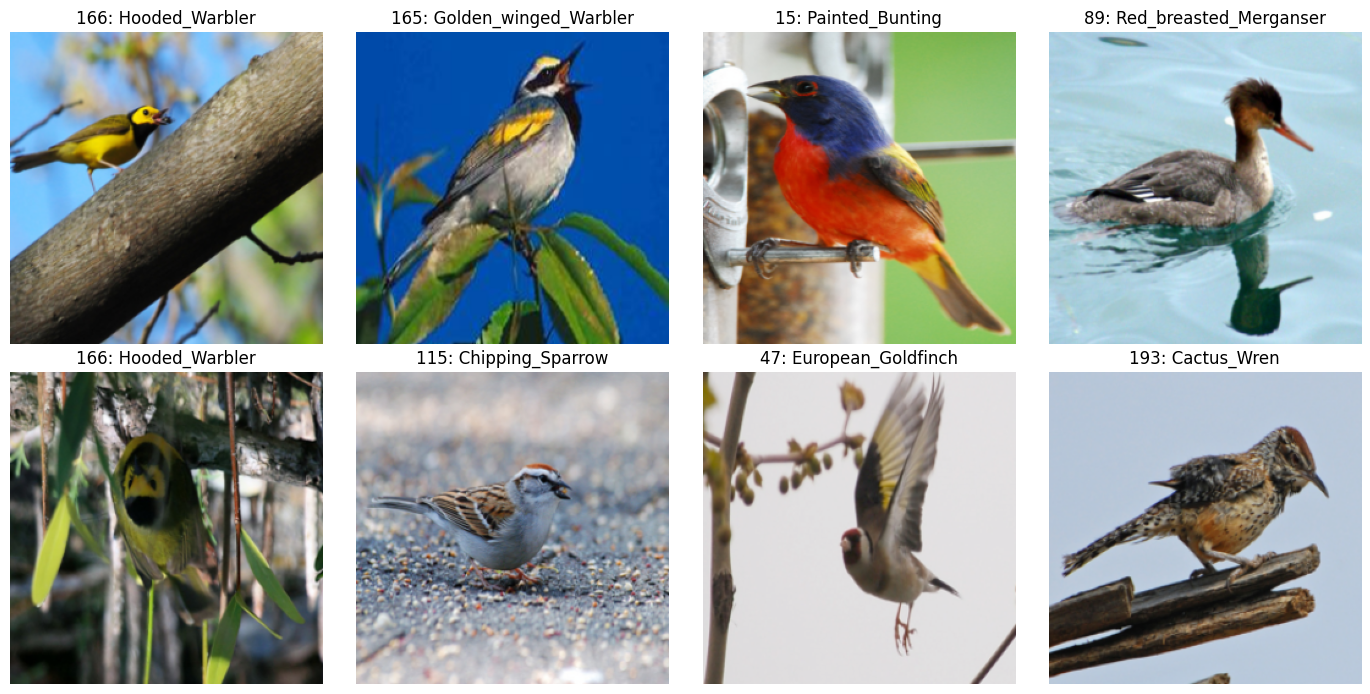

In [12]:
class_counts = pd.Series(train_source.targets[official_train_indices]).value_counts().sort_index()
display(pd.DataFrame({'class_id': class_counts.index, 'bird_name': [class_names[i] for i in class_counts.index], 'count': class_counts.values}))

sample_images, sample_labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for image_tensor, label, ax in zip(sample_images[:8], sample_labels[:8], axes.flat):
    image = image_tensor.permute(1, 2, 0).numpy() * np.asarray(imagenet_std) + np.asarray(imagenet_mean)
    ax.imshow(np.clip(image, 0, 1))
    ax.set_title(f'{int(label)}: {class_names[int(label)]}')
    ax.axis('off')
plt.tight_layout()
plt.show()

In [13]:
from pathlib import Path

p = Path(DINOV3_WEIGHTS)

print("Path:", p)
print("Exists:", p.exists())

if p.exists():
    print("Size:", p.stat().st_size / 1024**2, "MB")

Path: /content/dinov3_vits16_pretrain_lvd1689m-08c60483.pth
Exists: True
Size: 82.52245235443115 MB


## 5. Mô hình baseline ViT không TACS

Baseline này dùng backbone `dinov3_vits16` chính thức, lấy CLS embedding 384 chiều từ DINOv3 ViT-S/16 rồi thêm classification head 200 lớp. Toàn bộ backbone và head được fine-tune bằng AdamW theo cấu hình paper; không có Selector, retrieval hoặc context fusion.

In [14]:
class DinoV3NoContextClassifier(nn.Module):
    def __init__(self, repo_dir, model_name, weights, num_classes, feature_dim=384):
        super().__init__()
        repo_dir = Path(repo_dir)
        source = 'local' if repo_dir.is_dir() else 'github'
        repo_or_dir = str(repo_dir) if repo_dir.is_dir() else 'facebookresearch/dinov3'
        self.backbone = torch.hub.load(repo_or_dir, model_name, source=source, weights=weights)
        self.head = nn.Linear(feature_dim, num_classes)

    def forward(self, images):
        features = self.backbone(images)
        if isinstance(features, dict):
            features = features['x_norm_clstoken']
        return self.head(features)

def resolve_dinov3_weights():
    path = Path(DINOV3_WEIGHTS)

    if not path.is_file():
        raise FileNotFoundError(f"Không tìm thấy file: {path}")

    if path.stat().st_size < 10 * 1024 * 1024:
        raise ValueError("File weight bị rỗng hoặc bị hỏng")

    return str(path)

def create_paper_vit_s16():
    network = DinoV3NoContextClassifier(
        repo_dir=DINOV3_REPO_DIR,
        model_name=DINOV3_MODEL_NAME,
        weights=resolve_dinov3_weights(),
        num_classes=NUM_CLASSES,
        feature_dim=FEATURE_DIM,
    )
    print(f'Loaded DINOv3 backbone: {DINOV3_MODEL_NAME}')
    print(f'DINOv3 weights: {resolve_dinov3_weights()}')
    return network

model = create_paper_vit_s16().to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
checkpoint_path = OUTPUT_DIR / 'final_paper_no_context_vit_s16.pt'
print(model)

Downloading: "https://github.com/facebookresearch/dinov3/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "file:///content/dinov3_vits16_pretrain_lvd1689m-08c60483.pth" to /root/.cache/torch/hub/checkpoints/dinov3_vits16_pretrain_lvd1689m-08c60483.pth


100%|██████████| 82.5M/82.5M [00:00<00:00, 325MB/s]


Loaded DINOv3 backbone: dinov3_vits16
DINOv3 weights: /content/dinov3_vits16_pretrain_lvd1689m-08c60483.pth
DinoV3NoContextClassifier(
  (backbone): DinoVisionTransformer(
    (patch_embed): PatchEmbed(
      (proj): Conv2d(3, 384, kernel_size=(16, 16), stride=(16, 16))
      (norm): Identity()
    )
    (rope_embed): RopePositionEmbedding()
    (blocks): ModuleList(
      (0-11): 12 x SelfAttentionBlock(
        (norm1): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
        (attn): SelfAttention(
          (qkv): LinearKMaskedBias(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (ls1): LayerScale()
        (norm2): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
        (mlp): Mlp(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approxim

## 5. Training theo paper

Paper dùng 100 epochs và cosine annealing. Vì paper mô tả standard train/test split, notebook không dùng early stopping hay validation checkpoint selection. Checkpoint cuối epoch 100 được lưu để đánh giá official test.

In [15]:
def train_one_epoch(network, loader):
    network.train()
    total_loss = 0.0
    all_targets, all_predictions = [], []
    for images, targets in tqdm(loader, leave=False):
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = network(images)
        loss = criterion(logits, targets)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(network.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item() * images.size(0)
        all_targets.extend(targets.detach().cpu().numpy())
        all_predictions.extend(logits.argmax(dim=1).detach().cpu().numpy())
    return {
        'loss': total_loss / len(loader.dataset),
        'accuracy': accuracy_score(all_targets, all_predictions),
    }

history = []
for epoch in range(1, EPOCHS + 1):
    train_metrics = train_one_epoch(model, train_loader)
    scheduler.step()
    history.append({'epoch': epoch, **train_metrics, 'learning_rate': scheduler.get_last_lr()[0]})
    print(
        f"Epoch {epoch:03d}/{EPOCHS} | "
        f"train loss {train_metrics['loss']:.4f} | "
        f"train top-1 accuracy {train_metrics['accuracy']:.4f} | "
        f"lr {scheduler.get_last_lr()[0]:.2e}"
    )

torch.save({
    'model_state_dict': model.state_dict(),
    'class_names': class_names,
    'architecture': BACKBONE_NAME,
    'feature_dim': FEATURE_DIM,
    'dinov3_model_name': DINOV3_MODEL_NAME,
    'dinov3_repo_dir': DINOV3_REPO_DIR,
    'dinov3_weights': resolve_dinov3_weights(),
    'image_size': IMAGE_SIZE,
    'mean': imagenet_mean,
    'std': imagenet_std,
    'epochs': EPOCHS,
    'batch_size': BATCH_SIZE,
    'seed': SEED,
    'pretraining': 'DINOv3',
}, checkpoint_path)
history_df = pd.DataFrame(history)
history_df.to_csv(OUTPUT_DIR / 'training_history.csv', index=False)
print('Saved:', checkpoint_path.resolve())

  0%|          | 0/94 [00:00<?, ?it/s]

Epoch 001/100 | train loss 5.0131 | train top-1 accuracy 0.0677 | lr 1.00e-04


  0%|          | 0/94 [00:00<?, ?it/s]

Epoch 002/100 | train loss 4.2279 | train top-1 accuracy 0.3278 | lr 9.99e-05


  0%|          | 0/94 [00:00<?, ?it/s]

Epoch 003/100 | train loss 3.4046 | train top-1 accuracy 0.5906 | lr 9.98e-05


... (190 outputs left out)

  0%|          | 0/94 [00:00<?, ?it/s]

Epoch 099/100 | train loss 0.0006 | train top-1 accuracy 1.0000 | lr 2.47e-08


  0%|          | 0/94 [00:00<?, ?it/s]

Epoch 100/100 | train loss 0.0006 | train top-1 accuracy 1.0000 | lr 0.00e+00
Saved: /content/outputs/baseline_paper_no_context_cub/final_paper_no_context_vit_s16.pt


In [16]:
# torch.save(model.state_dict(), OUTPUT_DIR / 'interrupted_model_checkpoint.pt')
# print("Đã lưu checkpoint thành công!")

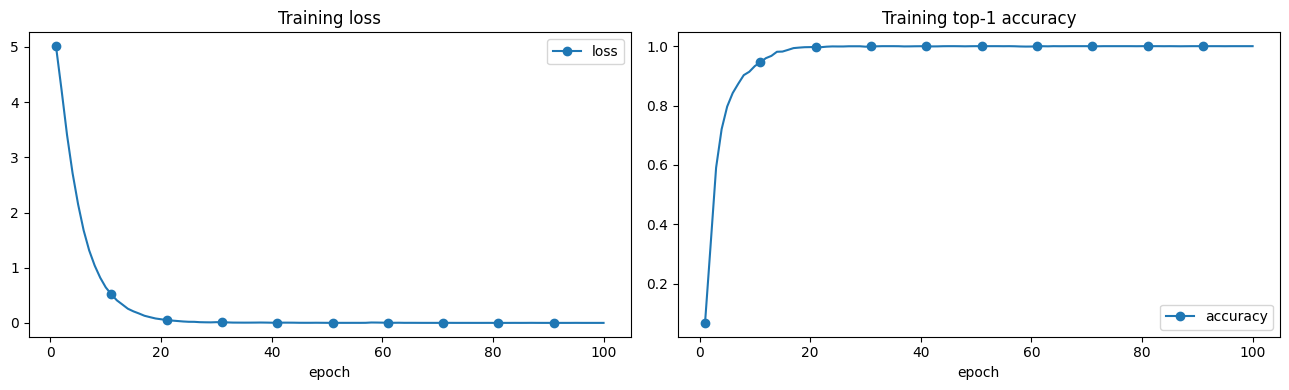

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
history_df.plot(x='epoch', y='loss', ax=axes[0], marker='o', markevery=max(1, len(history_df) // 10), title='Training loss')
history_df.plot(x='epoch', y='accuracy', ax=axes[1], marker='o', markevery=max(1, len(history_df) // 10), title='Training top-1 accuracy')
plt.tight_layout()
plt.show()

## 6. Official test evaluation

Paper dùng top-1 accuracy cho CUB. Notebook báo cáo `test_top1_accuracy` là metric chính; Macro-F1 được lưu thêm để phân tích phụ. Không dùng test để chọn epoch.

Test top-1 accuracy: 0.8253
Test macro-F1 supplementary: 0.8254


,precision,recall,f1-score,support
Black_footed_Albatross,0.807692,0.700000,0.750000,30.0
Laysan_Albatross,0.800000,0.800000,0.800000,30.0
Sooty_Albatross,0.722222,0.928571,0.812500,28.0
Groove_billed_Ani,0.783784,0.966667,0.865672,30.0
Crested_Auklet,0.800000,0.857143,0.827586,14.0


,true_class_id,true_bird_name,predicted_class_id,predicted_bird_name,confidence
0,0,Black_footed_Albatross,1,Laysan_Albatross,0.809811
1,0,Black_footed_Albatross,0,Black_footed_Albatross,0.997127
2,0,Black_footed_Albatross,0,Black_footed_Albatross,0.997847
3,0,Black_footed_Albatross,2,Sooty_Albatross,0.996517
4,0,Black_footed_Albatross,0,Black_footed_Albatross,0.979305


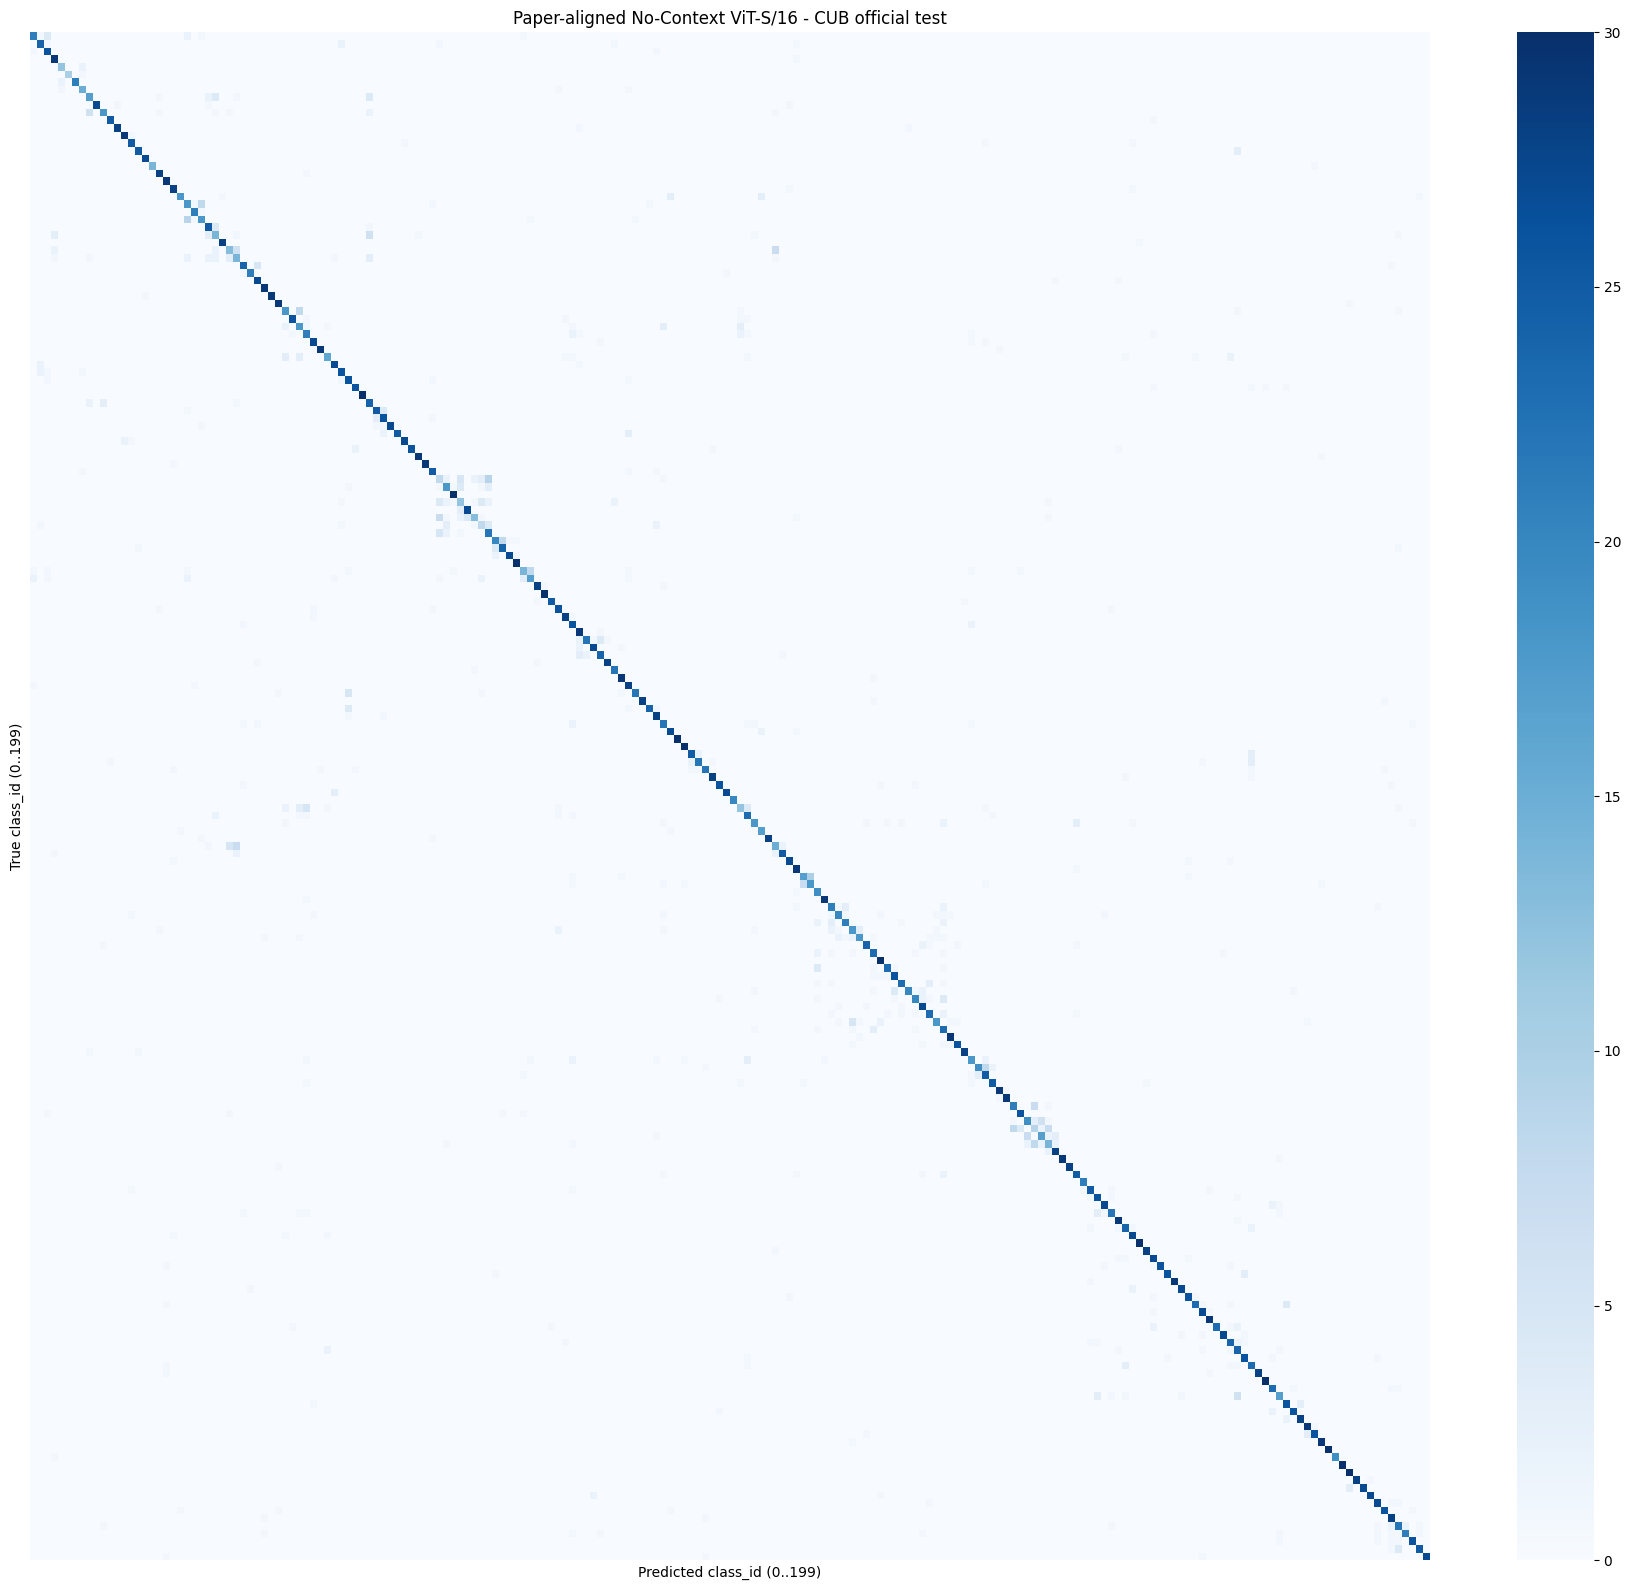

In [18]:
model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE)['model_state_dict'])
model.eval()

def predict_loader(network, loader):
    targets, predictions, probabilities = [], [], []
    with torch.inference_mode():
        for images, batch_targets in loader:
            logits = network(images.to(DEVICE))
            probs = torch.softmax(logits, dim=1).cpu().numpy()
            probabilities.append(probs)
            targets.extend(batch_targets.numpy())
            predictions.extend(probs.argmax(axis=1))
    return np.asarray(targets), np.asarray(predictions), np.concatenate(probabilities)

y_true, y_pred, y_prob = predict_loader(model, test_loader)
test_top1_accuracy = accuracy_score(y_true, y_pred)
test_macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
print(f'Test top-1 accuracy: {test_top1_accuracy:.4f}')
print(f'Test macro-F1 supplementary: {test_macro_f1:.4f}')

report = classification_report(y_true, y_pred, labels=np.arange(NUM_CLASSES), target_names=class_names, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T
report_df.to_csv(OUTPUT_DIR / 'classification_report.csv')

test_prediction_df = pd.DataFrame({
    'true_class_id': y_true,
    'true_bird_name': [class_names[int(index)] for index in y_true],
    'predicted_class_id': y_pred,
    'predicted_bird_name': [class_names[int(index)] for index in y_pred],
    'confidence': y_prob.max(axis=1),
})
test_prediction_df.to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)
display(report_df.head())
display(test_prediction_df.head())

cm = confusion_matrix(y_true, y_pred, labels=np.arange(NUM_CLASSES))
plt.figure(figsize=(18, 16))
sns.heatmap(cm, cmap='Blues', xticklabels=False, yticklabels=False)
plt.xlabel('Predicted class_id (0..199)')
plt.ylabel('True class_id (0..199)')
plt.title('Paper-aligned No-Context ViT-S/16 - CUB official test')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=160)
plt.show()

with open(OUTPUT_DIR / 'metrics.json', 'w', encoding='utf-8') as file:
    json.dump({
        'test_top1_accuracy': float(test_top1_accuracy),
        'test_macro_f1_supplementary': float(test_macro_f1),
        'num_classes': NUM_CLASSES,
        'architecture': BACKBONE_NAME,
        'pretraining': 'DINOv3',
        'image_size': IMAGE_SIZE,
        'batch_size': BATCH_SIZE,
        'epochs': EPOCHS,
        'seed': SEED,
    }, file, ensure_ascii=False, indent=2)

## 8. Dự đoán tên chim và class_id cho một ảnh

Hàm inference trả về `class_id` trong khoảng `0..199`, tên chim tương ứng và xác suất. Ví dụ: `class_id=0` là Black_footed_Albatross theo danh sách CUB.

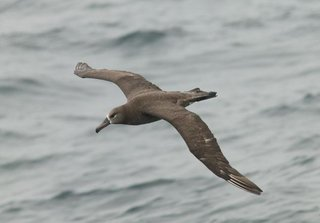

Predicted class_id: 0
Predicted bird name: Black_footed_Albatross


,class_id,bird_name,probability
0,0,Black_footed_Albatross,99.8785%
1,2,Sooty_Albatross,0.0458%
2,44,Northern_Fulmar,0.0243%
3,1,Laysan_Albatross,0.0044%
4,51,Pied_billed_Grebe,0.0024%


In [19]:
def predict_one_image(image_path, network=model, top_k=TOP_K):
    image_path = Path(image_path)
    if not image_path.is_file():
        raise FileNotFoundError(f'Không tìm thấy ảnh: {image_path.resolve()}')
    image = Image.open(image_path).convert('RGB')
    tensor = eval_transform(image).unsqueeze(0).to(DEVICE)
    network.eval()
    with torch.no_grad():
        probabilities = torch.softmax(network(tensor), dim=1)[0]
    top_k = min(top_k, NUM_CLASSES)
    values, indices = torch.topk(probabilities, k=top_k)
    result = pd.DataFrame({
        'class_id': [int(index) for index in indices.cpu()],
        'bird_name': [class_names[int(index)] for index in indices.cpu()],
        'probability': values.cpu().numpy(),
    })
    display(image)
    print(f"Predicted class_id: {result.iloc[0]['class_id']}")
    print(f"Predicted bird name: {result.iloc[0]['bird_name']}")
    display(result.style.format({'probability': '{:.4%}'}))
    return result

# Sửa PREDICT_IMAGE nếu muốn dự đoán ảnh khác.
prediction = predict_one_image(PREDICT_IMAGE)

## 8. Tải checkpoint và dự đoán ở phiên chạy khác

Checkpoint `outputs/baseline_paper_no_context_cub/final_paper_no_context_vit_s16.pt` lưu weights của wrapper DINOv3 ViT-S/16, class names, preprocessing metadata và paper configuration. Khi load lại cần clone DINOv3 repo hoặc có internet để `torch.hub` tải repo/checkpoint.

In [20]:
def load_baseline_for_inference(checkpoint_file, device=DEVICE):
    saved = torch.load(checkpoint_file, map_location=device)
    weights = saved.get('dinov3_weights', resolve_dinov3_weights())
    loaded_model = DinoV3NoContextClassifier(
        repo_dir=saved.get('dinov3_repo_dir', DINOV3_REPO_DIR),
        model_name=saved.get('dinov3_model_name', saved.get('architecture', DINOV3_MODEL_NAME)),
        weights=weights,
        num_classes=len(saved['class_names']),
        feature_dim=saved.get('feature_dim', FEATURE_DIM),
    )
    loaded_model.load_state_dict(saved['model_state_dict'])
    loaded_model.to(device).eval()
    return loaded_model, saved['class_names']

print('Checkpoint:', checkpoint_path.resolve())
print('Class IDs: 0..199')
print('Pretraining:', 'DINOv3')

Checkpoint: /content/outputs/baseline_paper_no_context_cub/final_paper_no_context_vit_s16.pt
Class IDs: 0..199
Pretraining: DINOv3


## 9. Phạm vi và reproduction status

- Đây là No-Context baseline: chỉ một query image, không candidate pool và không context image.
- Paper-aligned: `dinov3_vits16` chính thức, checkpoint DINOv3 ViT-S/16 LVD-1689M, 256x256, batch 64, 100 epochs, AdamW, cosine annealing và augmentation theo paper.
- Metric chính trên CUB là official test top-1 accuracy.
- Paper báo cáo trung bình trên ba random seeds; hãy chạy notebook với `SEED` khác nhau và tổng hợp mean/std để khớp protocol đầy đủ.
- Không dùng Focal Loss, K-fold, ensemble hoặc early stopping trong baseline này.
- Nếu không tải được DINOv3 repo/checkpoint, notebook cần được trỏ tới đường dẫn local tương ứng trước khi train.